# 05 · Product tagging with machine learning

**Question:** can a model tag product titles (category, product type, colour, pattern) accurately enough to replace most manual catalogue tagging?

**Method** (code in `src/fdda/tagging/`; a classic ML tagger instead of the LLM in the original plan, so it runs locally at no cost):
* **Data:** H&M's ~105k articles. Input = product name + description; targets = H&M's own labels mapped to a fixed schema (`tagging` in `config/settings.yaml`).
* **Split by style** (`product_code`): colour variants share almost the same text, so a random article split would put near-duplicates in train and test. Train / validation / test = 72% / 8% / 20% of styles.
* **Models per field:** most-frequent label (baseline), logistic regression and XGBoost on TF-IDF word features (XGBoost uses the 3,000 most informative features); the best on validation is kept and every model is scored on the test styles.
* **Confidence:** each suggestion has a probability, so high-confidence tags can be auto-accepted and only the rest reviewed.

This notebook reads the outputs of `python -m fdda.tagging.run all`.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from fdda import viz
from fdda.config import load_settings, resolve_path

settings = load_settings()
T = resolve_path(settings, "reports") / "tagging"
FIGURES = resolve_path(settings, "figures")
FIELDS = settings["tagging"]["fields"]
THR = settings["tagging"]["auto_accept_threshold"]
NAMES = {
    "most_frequent": "Most-frequent baseline",
    "logreg": "Logistic regression",
    "xgboost": "XGBoost",
}
LABEL = {
    "category": "Category",
    "subcategory": "Product type",
    "primary_colour": "Colour",
    "pattern": "Pattern",
}

summary = json.loads((T / "summary.json").read_text())
metrics = pd.read_csv(T / "metrics.csv")
viz.apply_style()
pd.options.display.float_format = "{:,.3f}".format
print(
    f"{summary['articles']:,} articles in {summary['styles']:,} styles; split {summary['split_articles']}; "
    f"{summary['features']:,} TF-IDF features"
)

105,542 articles in 47,224 styles; split {'train': 75826, 'test': 21112, 'val': 8604}; 30,000 TF-IDF features


## 1. Accuracy on held-out styles

Test accuracy per field and model. The model to beat is the most-frequent label.

model,logreg_accuracy,most_frequent_accuracy,xgboost_accuracy,logreg_macro_f1,most_frequent_macro_f1,xgboost_macro_f1
field,,,,,,
category,0.979,0.400,0.976,0.959,0.057,0.948
subcategory,0.891,0.102,0.874,0.876,0.004,0.853
primary_colour,0.343,0.218,0.340,0.212,0.026,0.194
pattern,0.642,0.464,0.636,0.443,0.045,0.435


,chosen model,classes
category,Logistic regression,10
subcategory,Logistic regression,46
primary_colour,Logistic regression,14
pattern,Logistic regression,14


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


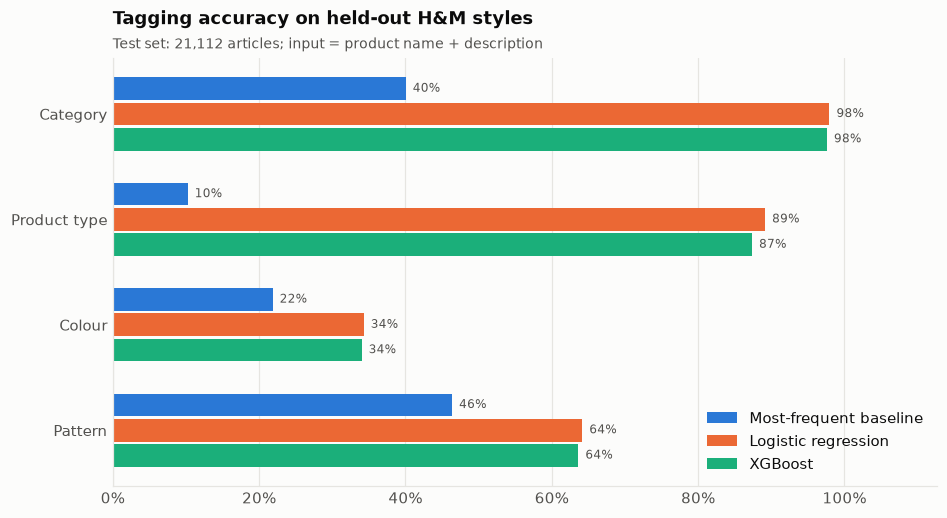

In [2]:
test = metrics[metrics.split == "test"]
acc = test.pivot(index="field", columns="model", values="accuracy").reindex(FIELDS)
f1 = test.pivot(index="field", columns="model", values="macro_f1").reindex(FIELDS)
display(acc.add_suffix("_accuracy").join(f1.add_suffix("_macro_f1")))
display(
    pd.DataFrame(
        {
            f: {"chosen model": NAMES[v["chosen_model"]], "classes": v["classes"]}
            for f, v in summary["fields"].items()
        }
    ).T
)

models = [m for m in ["most_frequent", "logreg", "xgboost"] if m in acc.columns]
fig, ax = viz.new_fig(8.5, 4.6)
viz.hbar(ax, [LABEL[f] for f in acc.index], {NAMES[m]: acc[m] for m in models})
viz.pct_axis(ax, "x")
ax.legend(loc="lower right", ncols=1)
ax.set_title("Tagging accuracy on held-out H&M styles", pad=22)
viz.subtitle(
    ax,
    f"Test set: {summary['split_articles'].get('test', 0):,} articles; input = product name + description",
)
viz.save_fig(fig, "tagging_accuracy_by_field", FIGURES)
plt.show()

## 2. How much can be auto-accepted?

For each confidence threshold: the share of products whose suggestion clears it (coverage) and how accurate those suggestions are. Moving right accepts more products automatically at lower accuracy.

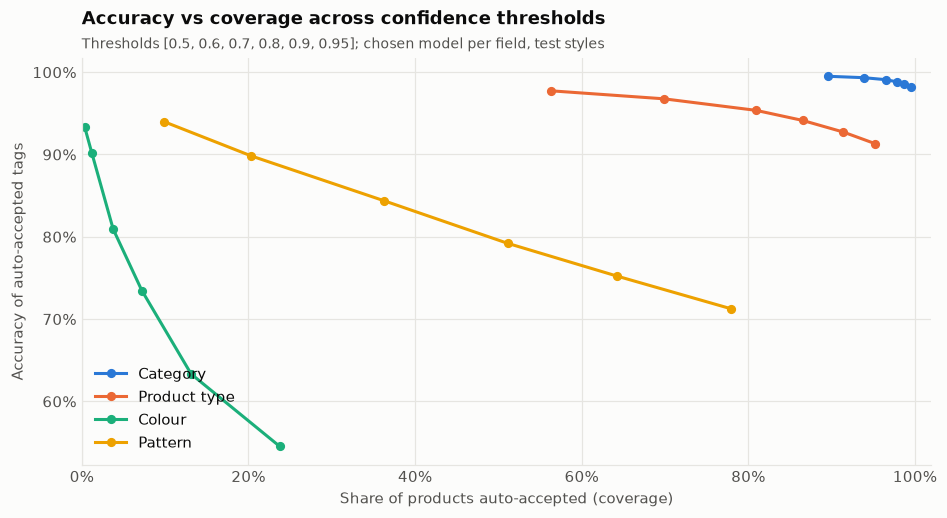

,threshold,coverage,accuracy_above,accuracy_below
category,0.900,0.939,0.993,0.766
subcategory,0.900,0.699,0.968,0.714
primary_colour,0.900,0.012,0.902,0.336
pattern,0.900,0.204,0.898,0.576


,combined (category + product type + pattern)
threshold,0.900
products,"21,112.000"
auto_accept_share,0.143
all_fields_correct_when_auto_accepted,0.897
all_fields_correct_overall,0.570


In [3]:
fig, ax = viz.new_fig(8.5, 4.6)
for i, f in enumerate(FIELDS):
    c = pd.read_csv(T / f"confidence_{f}.csv").sort_values("coverage")
    ax.plot(
        c["coverage"],
        c["accuracy_above"],
        marker="o",
        markersize=5,
        color=viz.SERIES[i],
        label=LABEL[f],
    )
viz.pct_axis(ax, "x")
viz.pct_axis(ax, "y")
ax.set_xlim(0, 1.02)
ax.set_xlabel("Share of products auto-accepted (coverage)")
ax.set_ylabel("Accuracy of auto-accepted tags")
ax.legend(loc="lower left")
ax.set_title("Accuracy vs coverage across confidence thresholds", pad=22)
viz.subtitle(
    ax,
    f"Thresholds {settings['tagging']['confidence_thresholds']}; chosen model per field, test styles",
)
viz.save_fig(fig, "tagging_accuracy_vs_coverage", FIGURES)
plt.show()

per_field = pd.DataFrame(summary["auto_accept"]["per_field"]).T
display(per_field)
display(
    pd.Series(
        summary["auto_accept"]["combined"], name="combined (category + product type + pattern)"
    ).to_frame()
)

## 3. Where the product-type model goes wrong

Rows = true type (15 most common), columns = predicted; each row shows shares.

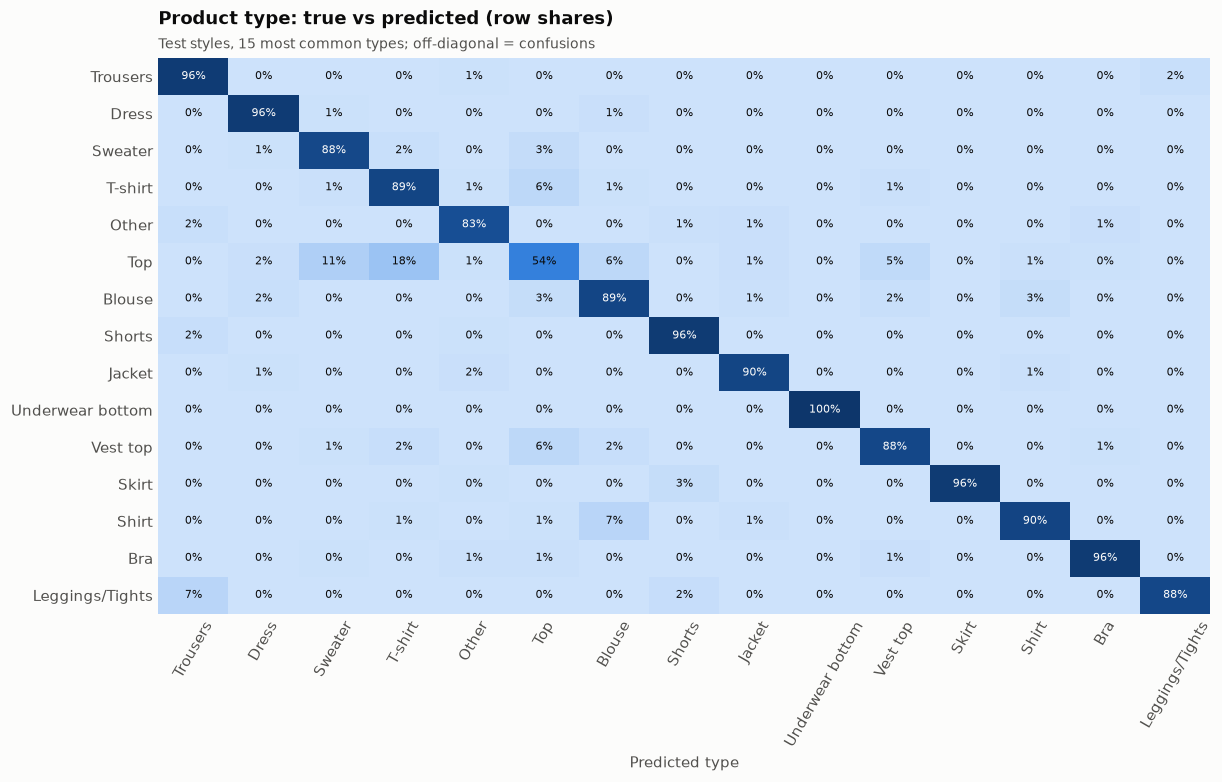

,label,precision,recall,f1,support
42,Trousers,0.958,0.959,0.958,"2,159.000"
12,Dress,0.963,0.956,0.960,"2,097.000"
37,Sweater,0.878,0.876,0.877,"1,912.000"
40,T-shirt,0.824,0.895,0.858,"1,398.000"
23,Other,0.788,0.832,0.809,"1,008.000"
41,Top,0.679,0.536,0.599,925.000
5,Blouse,0.835,0.890,0.862,843.000
32,Shorts,0.948,0.961,0.955,820.000
19,Jacket,0.828,0.896,0.860,788.000
44,Underwear bottom,0.997,0.998,0.998,666.000


In [4]:
cm = pd.read_csv(T / "confusion_subcategory.csv", index_col=0)
cols = [c for c in cm.index if c in cm.columns]
share = cm[cols].div(cm.sum(axis=1), axis=0)
fig, ax = viz.new_fig(11, 7)
viz.sequential_heatmap(
    ax, share.to_numpy(dtype=float), list(share.index), list(share.columns), fmt="{:.0%}"
)
ax.tick_params(axis="x", labelrotation=60)
ax.set_xlabel("Predicted type")
ax.set_title("Product type: true vs predicted (row shares)", pad=22)
viz.subtitle(ax, "Test styles, 15 most common types; off-diagonal = confusions")
viz.save_fig(fig, "tagging_confusion_subcategory", FIGURES)
plt.show()

pc = pd.read_csv(T / "per_class_subcategory.csv")
display(
    pc[~pc.label.isin(["accuracy", "macro avg", "weighted avg"])]
    .sort_values("support", ascending=False)
    .head(15)
)

## 4. Titles only

Myntra listings have a title but no description. Scoring the same H&M test styles with the title alone shows how much accuracy drops without the description, a rough guide to how the model will do on Myntra.

,Name + description,Title only
Category,0.979,0.628
Product type,0.891,0.497
Colour,0.343,0.258
Pattern,0.642,0.506


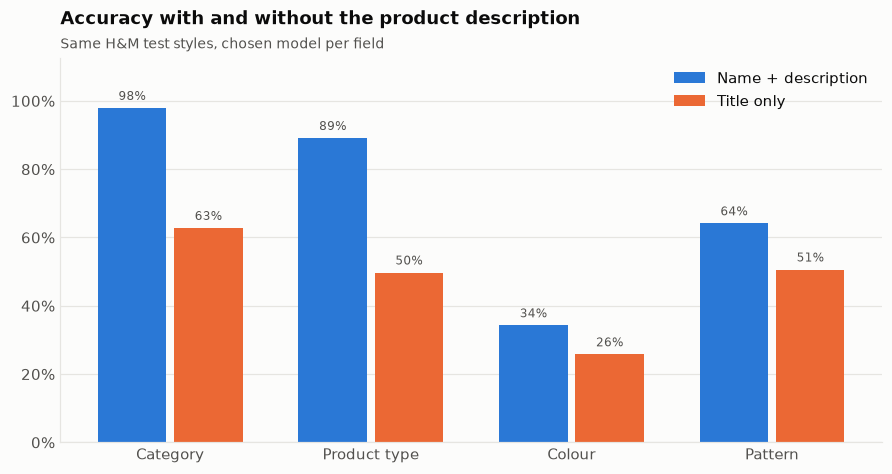

In [5]:
both = pd.DataFrame(
    {
        LABEL[f]: {
            "Name + description": v["test_accuracy"],
            "Title only": v["test_accuracy_title_only"],
        }
        for f, v in summary["fields"].items()
    }
).T
display(both)
fig, ax = viz.new_fig(8, 4.2)
viz.vbar(ax, list(both.index), {c: both[c] for c in both.columns})
viz.pct_axis(ax, "y")
ax.set_title("Accuracy with and without the product description", pad=22)
viz.subtitle(ax, "Same H&M test styles, chosen model per field")
viz.save_fig(fig, "tagging_title_only", FIGURES)
plt.show()

## 5. Tagging Myntra titles

The H&M-trained tagger applied to a sample of Myntra titles. There are no labels to score against, so this shows the suggested mix, the model's confidence, and how its categories line up with the rough keyword categories from notebook 01.

,median confidence,share with confidence >= 0.9
category,0.604,0.163
subcategory,0.440,0.072
primary_colour,0.359,0.004
pattern,0.674,0.150


,Accessories,Bottomwear,Footwear,Full-body garment,Innerwear,Nightwear & loungewear,Other,Socks & hosiery,Swimwear,Topwear
keyword_category,,,,,,,,,,
Bags & accessories,359,0,0,3,0,0,0,59,0,3
Beauty & personal care,324,1,0,48,3,0,51,0,0,46
Bottoms,62,322,0,2,2,0,0,0,1,12
Dresses & jumpsuits,4,1,0,107,1,0,0,0,0,0
Ethnic wear,229,67,0,41,0,1,0,0,0,156
Footwear,115,0,51,0,1,0,0,0,0,20
Home,188,17,0,33,0,0,0,0,0,62
Innerwear & nightwear,196,9,0,29,152,46,0,9,7,58
Jackets & sweaters,18,0,0,2,0,0,0,0,0,94


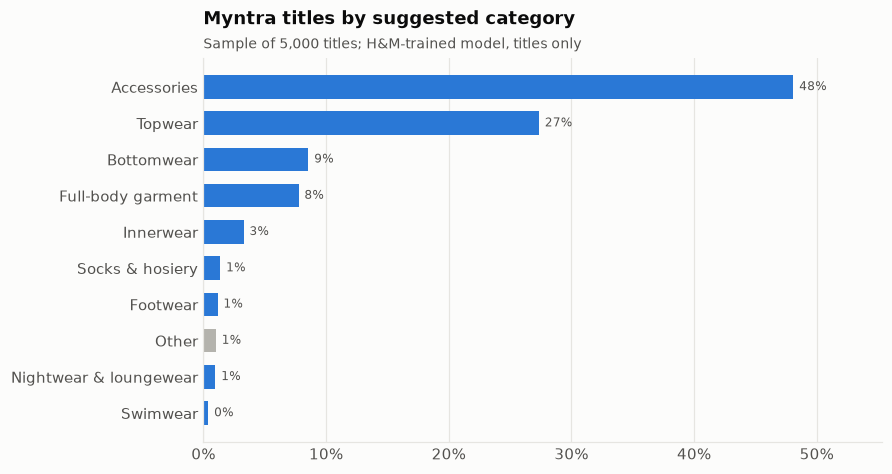

In [6]:
my = json.loads((T / "myntra_summary.json").read_text())
display(
    pd.DataFrame(
        {
            "median confidence": my["median_confidence"],
            f"share with confidence >= {THR}": my[f"share_confidence_at_least_{THR}"],
        }
    )
)
xt = pd.read_csv(T / "myntra_keyword_vs_model_category.csv", index_col=0)
display(xt)
dist = pd.read_csv(T / "myntra_tag_distribution.csv")
cat = dist[dist.field == "category"].set_index("value")["share"].sort_values(ascending=False)
fig, ax = viz.new_fig(8, 4.2)
viz.hbar(ax, list(cat.index), {"Share of Myntra titles": cat})
viz.pct_axis(ax, "x")
ax.set_title("Myntra titles by suggested category", pad=22)
viz.subtitle(ax, f"Sample of {my['items']:,} titles; H&M-trained model, titles only")
viz.save_fig(fig, "tagging_myntra_categories", FIGURES)
plt.show()

## 6. Timed effort study

Measured by hand: 100 products tagged from scratch vs 100 products whose model suggestions were reviewed and corrected (`python -m fdda.tagging.effort_study`). Effort reduction = 1 − review time ÷ manual time.

In [7]:
es_path = T / "effort_study.json"
if es_path.exists():
    es = json.loads(es_path.read_text())
    display(
        pd.DataFrame({k: es[k] for k in ["manual", "review"]}).T.drop(
            columns=["accuracy_vs_labels"], errors="ignore"
        )
    )
    print(
        f"Effort reduction: {es['effort_reduction']:.0%}"
        if es.get("effort_reduction") is not None
        else "Effort reduction: [TBD] (both arms needed)"
    )
else:
    print("Effort study not run yet: [TBD]. See the commands above.")

Effort study not run yet: [TBD]. See the commands above.


## 7. Key facts

Computed from `reports/tagging/summary.json`.

In [8]:
fields = summary["fields"]
comb = summary["auto_accept"]["combined"]
facts = pd.Series(
    {
        **{
            f"{LABEL[f]}: test accuracy (baseline)": f"{v['test_accuracy']:.1%} ({v['baseline_test_accuracy']:.1%})"
            for f, v in fields.items()
        },
        **{f"{LABEL[f]}: chosen model": NAMES[v["chosen_model"]] for f, v in fields.items()},
        f"Products with category, type and pattern all >= {THR} confidence": f"{comb['auto_accept_share']:.0%}",
        "... of which all three tags correct": f"{comb['all_fields_correct_when_auto_accepted']:.1%}",
    },
    name="value",
)
facts.to_frame()

,value
Category: test accuracy (baseline),97.9% (40.0%)
Product type: test accuracy (baseline),89.1% (10.2%)
Colour: test accuracy (baseline),34.3% (21.8%)
Pattern: test accuracy (baseline),64.2% (46.4%)
Category: chosen model,Logistic regression
Product type: chosen model,Logistic regression
Colour: chosen model,Logistic regression
Pattern: chosen model,Logistic regression
"Products with category, type and pattern all >= 0.9 confidence",14%
... of which all three tags correct,89.7%


**Reading the result.** Category and product type are learned well from text; pattern partly; colour poorly, because H&M descriptions rarely name the colour and colour variants share one description, so colour needs image data. Titles alone carry much less signal than titles plus descriptions, so Myntra suggestions are less reliable than the H&M test scores. The confidence scores make the tagger useful anyway: accept the confident suggestions automatically and send the rest to a person.